Part 1 — Load and Inspect the Dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
csv_path = Path("EDA_Campus_Cafe_Transactions.csv")
if not csv_path.exists():
    csv_path = Path("/mnt/data/EDA_Campus_Cafe_Transactions.csv")
raw = pd.read_csv("Jonathan_Atsu/EDA_Campus_Cafe_Transactions.csv")
display(raw.head())
print("Rows and columns:", raw.shape)
print("\nData types and missing counts:")
raw.info()
display(raw.describe(include="all"))
for col in ["Location", "Category", "Item", "PaymentMethod"]:
    print(f"\n{col} labels:")
    print(raw[col].value_counts(dropna=False).to_string())

,TransactionID,Date,Location,Category,Item,Quantity,UnitPrice,PaymentMethod,Satisfaction
0,T0001,10/6/2026,Science Building,Beverage,Smoothie,4,4.75,Card,4.0
1,T0002,9/1/2026,Library Cafe,Beverage,Coffee,1,2.75,Card,4.0
2,T0003,9/21/2026,Library Cafe,Beverage,Coffee,1,2.75,Card,4.0
3,T0004,9/22/2026,Student Center,Snack,Cookie,1,2.00,Mobile,5.0
4,T0005,10/13/2026,Student Center,Snack,Cookie,3,2.00,Card,4.0


Rows and columns: (151, 9)

Data types and missing counts:
<class 'pandas.DataFrame'>
RangeIndex: 151 entries, 0 to 150
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   TransactionID  151 non-null    str    
 1   Date           151 non-null    str    
 2   Location       151 non-null    str    
 3   Category       151 non-null    str    
 4   Item           151 non-null    str    
 5   Quantity       151 non-null    int64  
 6   UnitPrice      151 non-null    float64
 7   PaymentMethod  149 non-null    str    
 8   Satisfaction   147 non-null    float64
dtypes: float64(2), int64(1), str(6)
memory usage: 10.7 KB


,TransactionID,Date,Location,Category,Item,Quantity,UnitPrice,PaymentMethod,Satisfaction
count,151,151,151,151,151,151.000000,151.000000,149,147.000000
unique,150,61,6,6,9,NaN,NaN,3,NaN
top,T0037,9/21/2026,Student Center,Beverage,Salad,NaN,NaN,Card,NaN
freq,2,7,74,63,23,NaN,NaN,74,NaN
mean,NaN,NaN,NaN,NaN,NaN,1.589404,3.837748,NaN,3.863946
std,NaN,NaN,NaN,NaN,NaN,1.021577,2.126460,NaN,0.873032
min,NaN,NaN,NaN,NaN,NaN,-1.000000,0.000000,NaN,1.000000
25%,NaN,NaN,NaN,NaN,NaN,1.000000,2.000000,NaN,3.000000
50%,NaN,NaN,NaN,NaN,NaN,1.000000,2.750000,NaN,4.000000
75%,NaN,NaN,NaN,NaN,NaN,2.000000,6.500000,NaN,4.000000



Location labels:
Location
Student Center      74
Library Cafe        40
Science Building    34
student center       1
LIBRARY CAFE         1
Science building     1

Category labels:
Category
Beverage    63
Food        44
Snack       41
beverage     1
FOOD         1
 snack       1

Item labels:
Item
Salad            23
Coffee           21
Sandwich         21
Muffin           19
Bottled Water    16
Tea              15
Cookie           14
Smoothie         13
Chips             9

PaymentMethod labels:
PaymentMethod
Card      74
Mobile    41
Cash      34
NaN        2


The original file contains 151 rows and 9 columns. The Date column is text, not yet a date type. Some location and category labels use different capitalization or extra spaces. Payment method and satisfaction have missing entries. Quantity includes a negative number, unit price includes zero, and satisfaction includes a value above 5. These need investigation before calculating revenue.

Part 2 — Data Quality and Cleaning

In [3]:
print("Missing values by column:")
display(raw.isna().sum().to_frame("Missing"))
print("Exact duplicate rows:", raw.duplicated().sum())
print("Repeated transaction IDs:", raw.TransactionID.duplicated().sum())
display(raw[raw.duplicated(keep=False)])
for col in ["Location", "Category", "PaymentMethod"]:
    print(f"\nOriginal {col} values:", sorted(raw[col].dropna().unique()))
print("\nOriginal data types:")
print(raw.dtypes)
print("\nInvalid quantities:")
display(raw[raw.Quantity <= 0])
print("Invalid prices:")
display(raw[raw.UnitPrice <= 0])
print("Out-of-range satisfaction:")
display(raw[raw.Satisfaction.notna() & ~raw.Satisfaction.between(1, 5)])
print("Potential large quantities (>=5):")
display(raw[raw.Quantity >= 5])
print("Price ranges by item:")
display(raw.groupby("Item").UnitPrice.agg(["min", "max"]))

Missing values by column:


,Missing
TransactionID,0
Date,0
Location,0
Category,0
Item,0
Quantity,0
UnitPrice,0
PaymentMethod,2
Satisfaction,4


Exact duplicate rows: 1
Repeated transaction IDs: 1


,TransactionID,Date,Location,Category,Item,Quantity,UnitPrice,PaymentMethod,Satisfaction
36,T0037,9/28/2026,Science Building,Beverage,Tea,1,2.25,Mobile,4.0
150,T0037,9/28/2026,Science Building,Beverage,Tea,1,2.25,Mobile,4.0



Original Location values: ['LIBRARY CAFE', 'Library Cafe', 'Science Building', 'Science building', 'Student Center', 'student center ']

Original Category values: [' snack ', 'Beverage', 'FOOD', 'Food', 'Snack', 'beverage']

Original PaymentMethod values: ['Card', 'Cash', 'Mobile']

Original data types:
TransactionID        str
Date                 str
Location             str
Category             str
Item                 str
Quantity           int64
UnitPrice        float64
PaymentMethod        str
Satisfaction     float64
dtype: object

Invalid quantities:


,TransactionID,Date,Location,Category,Item,Quantity,UnitPrice,PaymentMethod,Satisfaction
44,T0045,10/29/2026,Library Cafe,Beverage,Bottled Water,-1,1.5,Card,3.0


... (4 outputs left out)

Potential large quantities (>=5):


,TransactionID,Date,Location,Category,Item,Quantity,UnitPrice,PaymentMethod,Satisfaction
72,T0073,10/20/2026,Library Cafe,Beverage,Tea,9,2.25,Card,5.0


Price ranges by item:


,min,max
Item,,
Bottled Water,1.50,1.50
Chips,1.75,1.75
Coffee,2.75,2.75
Cookie,2.00,2.00
Muffin,3.25,3.25
Salad,7.25,7.25
Sandwich,0.00,6.50
Smoothie,4.75,4.75
Tea,2.25,2.25


The cleaned analytical dataset below removes the one exact duplicate and the two transactions with invalid quantity/price. This is a sales-analysis choice, not a claim that those transactions never happened.

In [4]:
clean = raw.drop_duplicates().copy()
for col in ["Location", "Category", "Item", "PaymentMethod"]:
    clean[col] = clean[col].astype("string").str.strip()
clean["Location"] = clean["Location"].str.title()
clean["Category"] = clean["Category"].str.title()
clean["PaymentMethod"] = clean["PaymentMethod"].fillna("Unknown")
clean["Date"] = pd.to_datetime(clean["Date"], format="%m/%d/%Y", errors="coerce")
clean.loc[~clean["Satisfaction"].between(1, 5), "Satisfaction"] = np.nan
invalid_sales = clean[(clean["Quantity"] <= 0) | (clean["UnitPrice"] <= 0) | clean["Date"].isna()].copy()
print("Transactions excluded from sales analysis:")
display(invalid_sales)
clean = clean[(clean["Quantity"] > 0) & (clean["UnitPrice"] > 0) & clean["Date"].notna()].copy()
print("Original rows:", len(raw), "| Clean sales rows:", len(clean))
print("Missing values after cleaning:")
display(clean.isna().sum().to_frame("Missing"))
print("Normalized locations and categories:")
display(clean[["Location", "Category"]].nunique().to_frame("Unique labels"))

Transactions excluded from sales analysis:


,TransactionID,Date,Location,Category,Item,Quantity,UnitPrice,PaymentMethod,Satisfaction
44,T0045,2026-10-29,Library Cafe,Beverage,Bottled Water,-1,1.5,Card,3.0
92,T0093,2026-09-19,Science Building,Food,Sandwich,1,0.0,Cash,3.0


Original rows: 151 | Clean sales rows: 148
Missing values after cleaning:


,Missing
TransactionID,0
Date,0
Location,0
Category,0
Item,0
Quantity,0
UnitPrice,0
PaymentMethod,0
Satisfaction,5


Normalized locations and categories:


,Unique labels
Location,3
Category,3


Part- 3

1. How are order totals distributed, and do some orders cost much more than most? This helps describe a typical purchase and how much spending varies.


2. Which cafe locations and product categories bring in the most sales revenue? This helps compare sales performance and understand which products contribute most.


3. How does revenue change over time, and does the product mix differ by location? This helps identify daily fluctuations and possible differences in buying patterns between cafes.

Part-4 Descriptive and Grouped Analysis

In [5]:
clean["OrderTotal"] = clean["Quantity"] * clean["UnitPrice"]
print("Overall order and satisfaction statistics:")
display(clean[["Quantity", "UnitPrice", "OrderTotal", "Satisfaction"]].describe().round(2))
print("Total revenue: ${:,.2f}".format(clean.OrderTotal.sum()))
print("Median order: ${:.2f}; standard deviation: ${:.2f}".format(clean.OrderTotal.median(), clean.OrderTotal.std()))
location_summary = clean.groupby("Location").agg(Transactions=("TransactionID", "count"), Revenue=("OrderTotal", "sum"), AverageOrder=("OrderTotal", "mean")).sort_values("Revenue", ascending=False)
category_summary = clean.groupby("Category").agg(Transactions=("TransactionID", "count"), Revenue=("OrderTotal", "sum"), AverageOrder=("OrderTotal", "mean")).sort_values("Revenue", ascending=False)
print("\nBy location:")
display(location_summary.round(2))
print("By category:")
display(category_summary.round(2))
item_summary = clean.groupby("Item").agg(Revenue=("OrderTotal", "sum"), Units=("Quantity", "sum")).sort_values("Revenue", ascending=False)
print("By item:")
display(item_summary.round(2))
print("Top revenue item:", item_summary.Revenue.idxmax(), "(${:,.2f})".format(item_summary.Revenue.max()))
print("Top quantity item:", item_summary.Units.idxmax(), "({} units)".format(item_summary.Units.max()))
location_category = clean.pivot_table(index="Location", columns="Category", values="OrderTotal", aggfunc="sum", fill_value=0)
print("Location × Category revenue pivot table:")
display(location_category.round(2))

Overall order and satisfaction statistics:


,Quantity,UnitPrice,OrderTotal,Satisfaction
count,148.00,148.00,148.00,143.00
mean,1.61,3.89,6.09,3.86
std,1.01,2.11,4.80,0.86
min,1.00,1.50,1.50,1.00
25%,1.00,2.00,2.75,3.00
50%,1.00,3.25,5.38,4.00
75%,2.00,6.50,7.25,4.00
max,9.00,7.25,29.00,5.00


Total revenue: $901.75
Median order: $5.38; standard deviation: $4.80

By location:


,Transactions,Revenue,AverageOrder
Location,,,
Student Center,75,459.00,6.12
Library Cafe,40,266.75,6.67
Science Building,33,176.00,5.33


By category:


,Transactions,Revenue,AverageOrder
Category,,,
Food,44,422.50,9.60
Beverage,62,307.75,4.96
Snack,42,171.50,4.08


By item:


,Revenue,Units
Item,,
Salad,232.00,32
Sandwich,188.50,29
Smoothie,128.25,27
Muffin,91.00,28
Coffee,79.75,29
Tea,74.25,33
Cookie,48.00,24
Chips,31.50,18
Bottled Water,28.50,19


Top revenue item: Salad ($232.00)
Top quantity item: Tea (33 units)
Location × Category revenue pivot table:


Category,Beverage,Food,Snack
Location,,,
Library Cafe,109.75,130.25,26.75
Science Building,59.75,55.75,60.50
Student Center,138.25,236.50,84.25


In [6]:
top_loc = location_summary.index[0]
top_cat = category_summary.index[0]
top_item_revenue = item_summary.Revenue.idxmax()
top_item_units = item_summary.Units.idxmax()
print(f"Interpretation: {top_loc} generated the most revenue (${location_summary.iloc[0].Revenue:,.2f}), while {top_cat} was the largest category (${category_summary.iloc[0].Revenue:,.2f}).")
print(f"A typical order cost ${clean.OrderTotal.median():.2f} (median), compared with a mean of ${clean.OrderTotal.mean():.2f}. This comparison helps show whether larger orders pull the mean upward.")
print(f"{top_item_revenue} produced the highest item revenue, while {top_item_units} had the highest number of units sold. Revenue and units measure different things.")

Interpretation: Student Center generated the most revenue ($459.00), while Food was the largest category ($422.50).
A typical order cost $5.38 (median), compared with a mean of $6.09. This comparison helps show whether larger orders pull the mean upward.
Salad produced the highest item revenue, while Tea had the highest number of units sold. Revenue and units measure different things.


Part - 5 

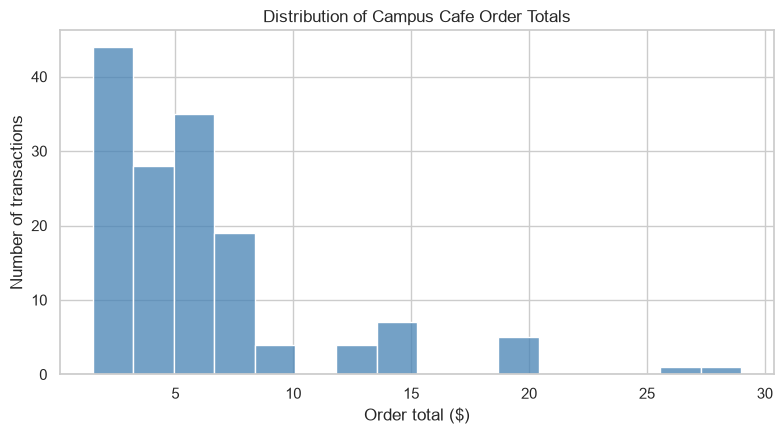

Interpretation: The median order is $5.38, while the maximum is $29.00. The larger orders stretch the right side of the distribution.


In [7]:
plt.figure(figsize=(8, 4.5))
sns.histplot(data=clean, x="OrderTotal", bins=16, color="steelblue")
plt.title("Distribution of Campus Cafe Order Totals")
plt.xlabel("Order total ($)")
plt.ylabel("Number of transactions")
plt.tight_layout()
plt.show()
print(f"Interpretation: The median order is ${clean.OrderTotal.median():.2f}, while the maximum is ${clean.OrderTotal.max():.2f}. The larger orders stretch the right side of the distribution.")

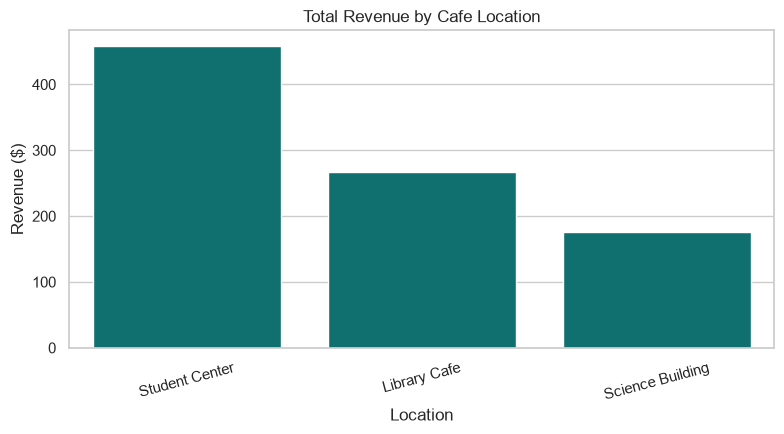

Interpretation: Student Center has the highest total revenue. This may reflect transaction volume as well as the value of individual orders; it does not by itself prove higher profitability.


In [8]:
plt.figure(figsize=(8, 4.5))
sns.barplot(x=location_summary.index, y=location_summary.Revenue, color="teal")
plt.title("Total Revenue by Cafe Location")
plt.xlabel("Location")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
print(f"Interpretation: {top_loc} has the highest total revenue. This may reflect transaction volume as well as the value of individual orders; it does not by itself prove higher profitability.")

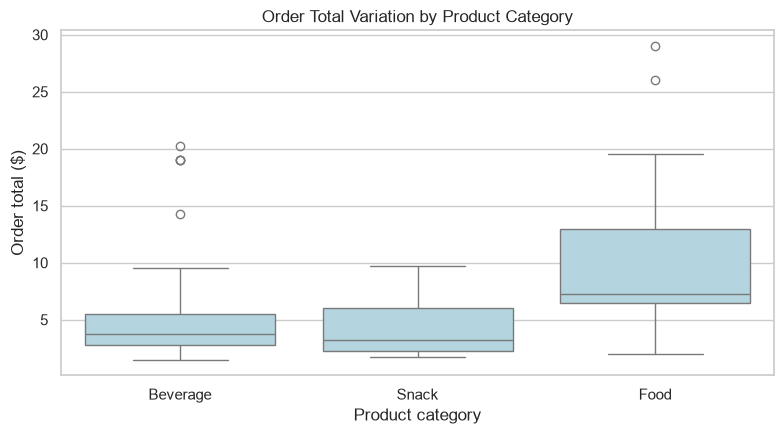

Interpretation: The boxes compare the middle half of order values in each category. Points outside the whiskers may be unusual orders, but they are not automatically mistakes.
Category medians ($): {'Beverage': 3.75, 'Food': 7.25, 'Snack': 3.25}


In [9]:
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=clean, x="Category", y="OrderTotal", color="lightblue")
plt.title("Order Total Variation by Product Category")
plt.xlabel("Product category")
plt.ylabel("Order total ($)")
plt.tight_layout()
plt.show()
print("Interpretation: The boxes compare the middle half of order values in each category. Points outside the whiskers may be unusual orders, but they are not automatically mistakes.")
print("Category medians ($):", clean.groupby("Category").OrderTotal.median().round(2).to_dict())

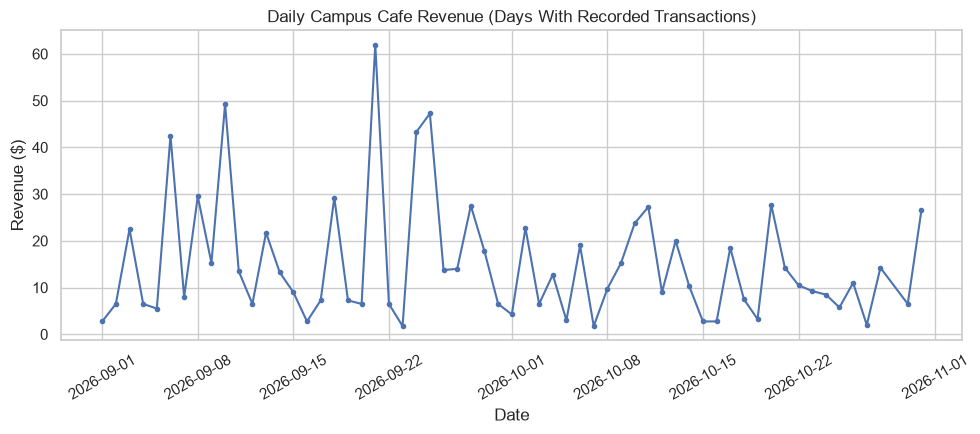

Interpretation: Daily revenue changes from date to date. The highest recorded day was September 21, 2026 ($62.00). Only days represented in the dataset are plotted; missing dates are not assumed to have zero sales.


In [10]:
daily_revenue = clean.groupby("Date").OrderTotal.sum().sort_index()
plt.figure(figsize=(10, 4.5))
plt.plot(daily_revenue.index, daily_revenue.values, marker="o", markersize=3)
plt.title("Daily Campus Cafe Revenue (Days With Recorded Transactions)")
plt.xlabel("Date")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()
print(f"Interpretation: Daily revenue changes from date to date. The highest recorded day was {daily_revenue.idxmax():%B %d, %Y} (${daily_revenue.max():.2f}). Only days represented in the dataset are plotted; missing dates are not assumed to have zero sales.")

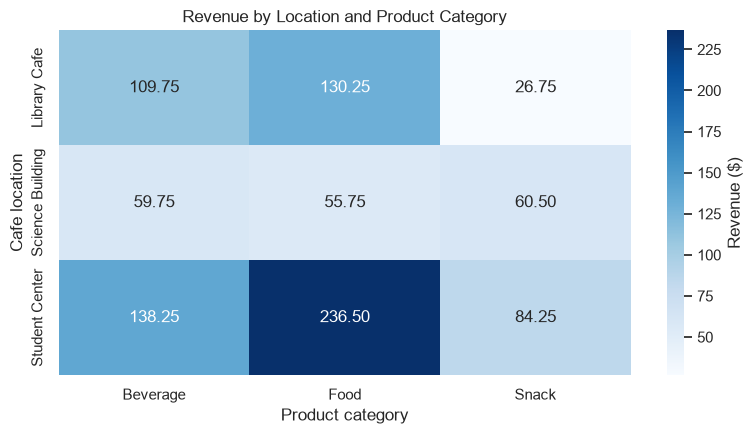

Interpretation: The largest location-category revenue combination is Student Center / Food ($236.50). This heatmap shows how category revenue varies across locations.


In [11]:
plt.figure(figsize=(8, 4.5))
sns.heatmap(location_category, annot=True, fmt=".2f", cmap="Blues", cbar_kws={"label": "Revenue ($)"})
plt.title("Revenue by Location and Product Category")
plt.xlabel("Product category")
plt.ylabel("Cafe location")
plt.tight_layout()
plt.show()
max_pair = location_category.stack().idxmax()
print(f"Interpretation: The largest location-category revenue combination is {max_pair[0]} / {max_pair[1]} (${location_category.loc[max_pair]:.2f}). This heatmap shows how category revenue varies across locations.")

PART - 6  Findings, Conclusions, and Limitations

In [12]:
monthly_revenue = clean.groupby(clean.Date.dt.to_period("M")).OrderTotal.sum()
print("Answers to the three analytical questions:")
print(f"1. Orders range from ${clean.OrderTotal.min():.2f} to ${clean.OrderTotal.max():.2f}; the median is ${clean.OrderTotal.median():.2f} and the mean is ${clean.OrderTotal.mean():.2f}. Larger purchases create variation in order totals.")
print(f"2. {top_loc} leads locations with ${location_summary.iloc[0].Revenue:,.2f} in revenue; {top_cat} leads categories with ${category_summary.iloc[0].Revenue:,.2f}.")
print(f"3. The highest recorded daily revenue is ${daily_revenue.max():.2f} on {daily_revenue.idxmax():%B %d, %Y}. The largest location-category combination is {max_pair[0]} / {max_pair[1]}.")
print("\nThree important findings:")
print(f"• Total cleaned sales revenue is ${clean.OrderTotal.sum():,.2f} across {len(clean)} transactions.")
print(f"• {top_item_revenue} earns the most item revenue (${item_summary.Revenue.max():,.2f}).")
print(f"• {top_item_units} sells the most units ({item_summary.Units.max():.0f}).")
print("\nMonthly revenue:")
print(monthly_revenue.to_string())

Answers to the three analytical questions:
1. Orders range from $1.50 to $29.00; the median is $5.38 and the mean is $6.09. Larger purchases create variation in order totals.
2. Student Center leads locations with $459.00 in revenue; Food leads categories with $422.50.
3. The highest recorded daily revenue is $62.00 on September 21, 2026. The largest location-category combination is Student Center / Food.

Three important findings:
• Total cleaned sales revenue is $901.75 across 148 transactions.
• Salad earns the most item revenue ($232.00).
• Tea sells the most units (33).

Monthly revenue:
Date
2026-09    545.50
2026-10    356.25
Freq: M


Limitations and cautions: This is a small, synthetic dataset covering only September and October 2026. The data may not represent the full cafe business. We excluded a negative-quantity transaction and a zero-price transaction because their meaning was unknown; a real business should check the original records before making permanent corrections. Missing satisfaction ratings cannot be used in averages. A day with no record is not necessarily a day with zero sales. Revenue is not profit because expenses are unavailable.

Final conclusion: The cleaned data helps compare typical order values, sales performance by location and category, and changes in daily revenue. The numerical tables and five graphs together show where recorded revenue is concentrated and how purchases vary. These patterns are useful for forming questions about cafe operations, but broader data would be needed before making strong business decisions.

Part - 7

